# 00 · Problem setup and network structure

Reproduction of **Souza, Levy & Costa, "Optimization of cooling water system hydraulic
debottlenecking", Applied Thermal Engineering 128 (2018) 1531-1542**
([doi:10.1016/j.applthermaleng.2017.09.089](https://doi.org/10.1016/j.applthermaleng.2017.09.089)).

This notebook loads the case study (every number of Section 3.1 lives in a single YAML
file), draws the network (Fig. 1), derives the hydraulic circuits (Table 1) and prints the
problem data (Tables 2-7). The last section shows how to **change any parameter, including
the network layout**.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from coolingnet import build_network, load_case, paper_case
from coolingnet.config import dump_case, paper_case_path
from coolingnet.reporting import plot_network
from coolingnet.reporting import tables as T

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

case = paper_case()
print(case.name)
print("configuration file:", paper_case_path())

Souza, Levy & Costa (2018) - hydraulic debottlenecking example
configuration file: /Users/jaimenms/code/personal/paper-optimization-of-cooling-water-systems/src/coolingnet/data/paper_case.yaml


## Fig. 1 - the cooling water distribution network

Edges are pipes (numbered), one pump (edge 2) and five coolers (E-101 ... E-105). Node 1 is the
cooling tower basin (water supply) and node 10 the tower top (water return). The network is a
digraph described by its incidence matrix (Eq. 1); the hydraulic circuits (Eq. 3) are derived
automatically as the unique supply-to-return path through each cooler.

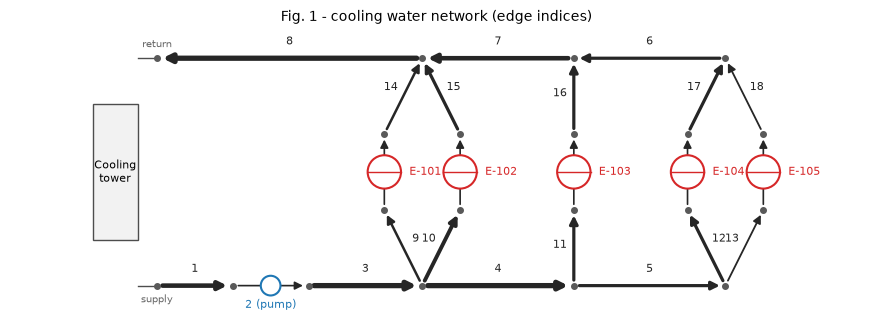

In [2]:
fig, ax = plt.subplots(figsize=(11, 5))
plot_network(case, ax=ax, title="Fig. 1 - cooling water network (edge indices)")
fig.savefig("../figures/fig01_network.png", dpi=150, bbox_inches="tight")

## Table 1 - hydraulic circuits

In [3]:
net = build_network(case.network)
T.table_circuits(case, net)

,Edges
Circuit,
1,"1, 2, 3, 9, E-101, 14, 8"
2,"1, 2, 3, 10, E-102, 15, 8"
3,"1, 2, 3, 4, 11, E-103, 16, 7, 8"
4,"1, 2, 3, 4, 5, 12, E-104, 17, 6, 7, 8"
5,"1, 2, 3, 4, 5, 13, E-105, 18, 6, 7, 8"


The incidence matrix $M_{t,k}$ (+1: edge enters node, -1: edge leaves node) and the circuit
matrix $\Lambda_{l,k}$ used by the mechanical energy balances:

In [4]:
incidence = pd.DataFrame(net.incidence, index=pd.Index(net.nodes, name="node"), columns=[net.label(e) for e in net.edge_ids])
circuits = pd.DataFrame(net.circuit_matrix, index=pd.Index([c.index for c in net.circuits], name="circuit"), columns=incidence.columns)
display(incidence.replace(0, "·"))
display(circuits.replace(0, "·"))

,1,2,3,4,5,6,7,8,9,10,...,14,15,16,17,18,E-101,E-102,E-103,E-104,E-105
node,,,,,,,,,,,,,,,,,,,,,
1,-1,·,·,·,·,·,·,·,·,·,...,·,·,·,·,·,·,·,·,·,·
2,1,-1,·,·,·,·,·,·,·,·,...,·,·,·,·,·,·,·,·,·,·
3,·,1,-1,·,·,·,·,·,·,·,...,·,·,·,·,·,·,·,·,·,·
4,·,·,1,-1,·,·,·,·,-1,-1,...,·,·,·,·,·,·,·,·,·,·
5,·,·,·,1,-1,·,·,·,·,·,...,·,·,·,·,·,·,·,·,·,·
6,·,·,·,·,1,·,·,·,·,·,...,·,·,·,·,·,·,·,·,·,·
7,·,·,·,·,·,-1,·,·,·,·,...,·,·,·,1,1,·,·,·,·,·
8,·,·,·,·,·,1,-1,·,·,·,...,·,·,1,·,·,·,·,·,·,·
9,·,·,·,·,·,·,1,-1,·,·,...,1,1,·,·,·,·,·,·,·,·


,1,2,3,4,5,6,7,8,9,10,...,14,15,16,17,18,E-101,E-102,E-103,E-104,E-105
circuit,,,,,,,,,,,,,,,,,,,,,
1,1,1,1,·,·,·,·,1,1,·,...,1,·,·,·,·,1,·,·,·,·
2,1,1,1,·,·,·,·,1,·,1,...,·,1,·,·,·,·,1,·,·,·
3,1,1,1,1,·,·,1,1,·,·,...,·,·,1,·,·,·,·,1,·,·
4,1,1,1,1,1,1,1,1,·,·,...,·,·,·,1,·,·,·,·,1,·
5,1,1,1,1,1,1,1,1,·,·,...,·,·,·,·,1,·,·,·,·,1


## Tables 2-7 - problem data

In [5]:
display(T.table_pipes(case))
display(T.table_pumps(case))
display(T.table_pump_cost_parameters(case))

,Length (m),Nominal diameter (in)
Pipe section,,
1,10.0,10.0
3,200.0,12.0
4,100.0,12.0
5,100.0,6.0
6,100.0,6.0
7,100.0,10.0
8,200.0,12.0
9,25.0,4.0
10,25.0,8.0


,a2,a1,a0
Alternative,,,
1,-415.6,-135.0,31.5
2,-498.7,-162.0,37.8
3,-554.1,-180.0,42.0
4,-609.5,-198.0,46.2


,Value
Factor,
F_I,2.800000
F_ms,1.300000
F_m,1.350000
b1,5.102900
b2,-1.221700
b3,0.077100
q_pu design (m3/s),0.095276


In [6]:
display(T.table_thermal_tasks(case))
display(T.table_exchanger_design(case))
display(T.table_problem_parameters(case))

,Flow rate hot/cold (kg/s),Inlet temperature hot/cold (C),Outlet temperature hot/cold (C),Heat capacity hot/cold (J/kg C)
Heat exchanger,,,,
E-101,12.00/11.80,80.00/32.00,65.00/40.00,2200/4187
E-102,12.00/28.70,120.00/32.00,80.00/40.00,2000/4187
E-103,10.50/35.60,80.00/32.00,40.00/40.00,2840/4187
E-104,8.50/15.60,69.00/32.00,41.00/40.00,2200/4187
E-105,1.70/3.10,69.00/32.00,41.00/40.00,2200/4187


,Area (m2),Film coefficient tube/shell (W/m2 C),Total fouling factor (1e-4 m2 C/W),Design head loss (m)
Heat exchanger,,,,
E-101,27.3,10615/658,5.1,5.53
E-102,76.7,10651/266,7.6,6.35
E-103,133.6,8864/923,4.8,4.82
E-104,109.5,6187/450,4.9,2.97
E-105,47.4,3645/216,4.9,1.20


,Value
Parameter,
Cooling water density (kg/m3),995.0
Cooling water heat capacity (J/kg C),4187.0
Maximum flow velocity (m/s),3.7
Minimum flow velocity (m/s),0.1
Hazen-Williams parameter c,120.0
Pipe cost parameters C1 / m,7.0386 / 1.4393
Pump efficiency,0.6
Number of operating hours per year (h/y),8760.0
Energy cost (USD/kWh),0.1


## Configuring the problem

Everything is data. Two ways to change the problem:

1. **Edit a YAML file.** Export the paper configuration and edit it (or run
   `coolingnet export-config my_case.yaml` from a shell). The `network.edges` list defines the
   digraph: add/remove pipes and coolers, change lengths, existing diameters, the pump option,
   node ids... `load_case("my_case.yaml")` validates everything (unique ids, catalogue
   diameters, cooler data present for every cooler edge, single path per cooler).
2. **Programmatically**, with `case.with_updates(...)` / pydantic `model_copy`.

Notebook `07_custom_network` walks through a complete example (a sixth cooler is added).

In [7]:
my_case_path = Path("../configs/my_case.yaml")
dump_case(case, my_case_path)
print(my_case_path.read_text()[:1200], "...")

name: Souza, Levy & Costa (2018) - hydraulic debottlenecking example
network:
  supply_node: 1
  return_node: 10
  elevation_difference_m: 5.0
  edges:
  - id: 1
    kind: pipe
    tail: 1
    head: 2
    length_m: 10.0
    diameter_in: 10.0
  - id: 2
    kind: pump
    tail: 2
    head: 3
    option: '1'
  - id: 3
    kind: pipe
    tail: 3
    head: 4
    length_m: 200.0
    diameter_in: 12.0
  - id: 4
    kind: pipe
    tail: 4
    head: 5
    length_m: 100.0
    diameter_in: 12.0
  - id: 5
    kind: pipe
    tail: 5
    head: 6
    length_m: 100.0
    diameter_in: 6.0
  - id: 6
    kind: pipe
    tail: 7
    head: 8
    length_m: 100.0
    diameter_in: 6.0
  - id: 7
    kind: pipe
    tail: 8
    head: 9
    length_m: 100.0
    diameter_in: 10.0
  - id: 8
    kind: pipe
    tail: 9
    head: 10
    length_m: 200.0
    diameter_in: 12.0
  - id: 9
    kind: pipe
    tail: 4
    head: 11
    length_m: 25.0
    diameter_in: 4.0
  - id: 10
    kind: pipe
    tail: 4
    head: 12
    len

In [8]:
# programmatic change: a stronger penalty and a cheaper energy price
alt = case.with_updates(
    heat_exchanger_defaults=case.heat_exchanger_defaults.model_copy(update={"penalty_factor_USD_per_C_y": 20000.0}),
    economics=case.economics.model_copy(update={"energy_cost_USD_kWh": 0.08}),
)
print("penalty factor:", alt.heat_exchanger("E-103").penalty_factor_USD_per_C_y, "USD/(y C)")
print("energy cost:", alt.economics.energy_cost_USD_kWh, "USD/kWh")

penalty factor: 20000.0 USD/(y C)
energy cost: 0.08 USD/kWh


Structural errors are reported explicitly. For instance, a second pipe in parallel to the
branch of E-101 creates two alternative paths, which the parallel-coolers model does not accept:

In [9]:
from coolingnet.config.schema import PipeEdge
from coolingnet.network import NetworkStructureError

bad_edges = list(case.network.edges) + [PipeEdge(id=99, tail=4, head=11, length_m=25, diameter_in=4)]
try:
    build_network(case.network.model_copy(update={"edges": bad_edges}))
except NetworkStructureError as err:
    print("NetworkStructureError:", err)

NetworkStructureError: 2 alternative paths upstream of E-101 (node 1 -> node 11); the model assumes coolers in parallel, each one in a single hydraulic circuit
